# Genetic Structure and Relatedness


- Do distinct genetic groups appear within or between breeds?
- LD pruning, PCA, UMAP, t-SNE, and relatedness estimation examine 164 dogs: 116 GSP and 48 LR.
- These methods describe genetic similarity, major axes of variation, and estimated sharing within breeds.
- They do not establish ancestry, pedigrees, or causes of training outcomes.

### (Initialization) Review Settings
- Saved results are read from the recorded output folder.
- New analysis requires QC data and PLINK 1.9
- Changed analyses require separate output folders

In [1]:
# Set repository, result and figure locations for the structure analysis.
# Separate run folders keep reproduced results apart from the original study outputs.

from pathlib import Path
import importlib
import hashlib
import json
import os
import shutil
import subprocess
import sys

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/notebook_review.py").exists()) / "scripts"))
require_saved = importlib.import_module("notebook_review").require_saved

study_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "scripts/genetic_structure.py").exists())
run_name = "version2-preview" if os.name == "nt" else "version2-preview-linux"
run_folder = study_root / "data/03-structure" / run_name
figure_folder = study_root / "results/private/03_structure" / run_name / "figures"
qc_file = study_root / "data/02-qc/manifest.private.json"

# Set this to your native PLINK executable if it is not already configured.
plink_executable = None

### (Parse) Load QC Data and Find PLINK
- Scheme B includes all primary-comparison dogs without duplication.
- The code checks the QC summary and PLINK version.

In [2]:
# Select the broader cohort once per breed and find a native PLINK 1.9 executable.
# This avoids duplicating primary-cohort dogs and checks that the required tool is available.

qc = json.loads(qc_file.read_text(encoding="utf-8"))
assert qc["status"] == "complete", "Complete Notebook 02 first."
genotype_prefixes = {
    dataset["breed"]: next(study_root / p.replace(chr(92), "/") for p in dataset["files"]
                           if p.endswith(".fam")).with_suffix("")
    for dataset in qc["datasets"]
    if dataset["scenario"] == "not-behelim-vs-behelim"
}
saved_environment = study_root / "data/01-processed/private/plink_environment.private.json"
if plink_executable is None and os.name == "nt" and saved_environment.exists():
    plink_executable = json.loads(saved_environment.read_text(encoding="utf-8"))["executable"]
local_plink = study_root / "data/02-tools" / (
    "plink-1.9.0-20260927-win64/plink.exe" if os.name == "nt"
    else "plink-1.9.0-20260927-linux64/plink"
)
plink_executable = plink_executable or (str(local_plink) if local_plink.is_file() else shutil.which("plink"))
if not plink_executable or not Path(plink_executable).is_file():
    raise FileNotFoundError("Install the project tool with: python scripts/setup_plink.py (from the repository), or set plink_executable.")
version = subprocess.check_output([str(plink_executable), "--version"], text=True)
assert "PLINK v1.9" in version, "This chapter uses PLINK 1.9."
print(version.strip())
print("QC data located for:", ", ".join(sorted(genotype_prefixes)))

PLINK v1.9.0 64-bit (27 Sep 2026)
QC data located for: GSP, LR


### PCA, UMAP and t-SNE
- PCA shows major axes of variation.
- UMAP and t-SNE use the first 20 weighted PCs to emphasize local similarity.
- Markers are pruned; outcomes only determine colors.
- Gaps and cluster sizes are not direct genetic distances or diversity measures.

| View | Dogs | Markers (Pruned) | Variation In PC1+PC2 |
| :---: | :---: | :---: | :---: |
| Both | 164 | 2,370 | 13.8% |
| GSP | 116 | 16,053 | 13.3% |
| LR | 48 | 17,268 | 15.5% |


### (Analysis) LD Pruning and Genetic Structure
- Saved results are checked against their inputs and script.
- Pruning uses a 50-marker window, five-marker step and r² cutoff of 0.2; maps include alternative settings and seeds.
- *genetic_structure.py*

In [3]:
# Reuse a completed structure run only when its script and QC manifest hashes match.
# Commented commands document how a separate structure analysis is calculated.

run_folder.mkdir(parents=True, exist_ok=True)
environment_file = run_folder / "plink_environment.private.json"
environment = {"executable": str(Path(plink_executable).resolve()),
               "executable_sha256": hashlib.sha256(Path(plink_executable).read_bytes()).hexdigest()}
script = study_root / "scripts/genetic_structure.py"
manifest_file = run_folder / "manifest.private.json"
require_saved(manifest_file)
if manifest_file.exists():
    manifest = json.loads(manifest_file.read_text(encoding="utf-8"))
    assert manifest["status"] == "complete"
    assert manifest["script_sha256"] == hashlib.sha256(script.read_bytes()).hexdigest(), "Choose a new run_name for changed code."
    assert manifest["qc_manifest_sha256"] == hashlib.sha256(qc_file.read_bytes()).hexdigest(), "Choose a new run_name for changed QC inputs."
    print("Using the completed preview run.")
# else:
#     from importlib.util import find_spec
#     required = ["numpy", "matplotlib", "sklearn", "threadpoolctl", "umap", "nbformat"]
#     missing = [name for name in required if find_spec(name) is None]
#     if missing:
#         raise ModuleNotFoundError(
#             "Rerunning the analysis needs: " + ", ".join(missing)
#             + ". Install scripts/requirements-structure.txt into this notebook's kernel with %pip."
#         )
#     environment_file.write_text(json.dumps(environment, indent=2), encoding="utf-8")
#     command = [sys.executable, str(script), "--root", str(study_root),
#                "--environment", str(environment_file), "--output", str(run_folder),
#                "--figures", str(figure_folder)]
#     subprocess.run(command, cwd=study_root, check=True)
#     manifest = json.loads(manifest_file.read_text(encoding="utf-8"))

Using the completed preview run.


### (Consistency Check) Check Saved Figures

In [4]:
# Define a figure-display helper that checks each saved image against its recorded hash.
# This ties the displayed plots to the verified structure run.

from IPython.display import Image, display

def display_figure(name):
    path = figure_folder / f"{name}.png"
    relative = path.relative_to(study_root).as_posix()
    figure_hashes = {key.replace(chr(92), "/"): value for key, value in manifest["figures"].items()}
    expected = figure_hashes[relative]
    assert hashlib.sha256(path.read_bytes()).hexdigest() == expected
    display(Image(filename=str(path)))

### (Visualization) German Shorthaired Pointers

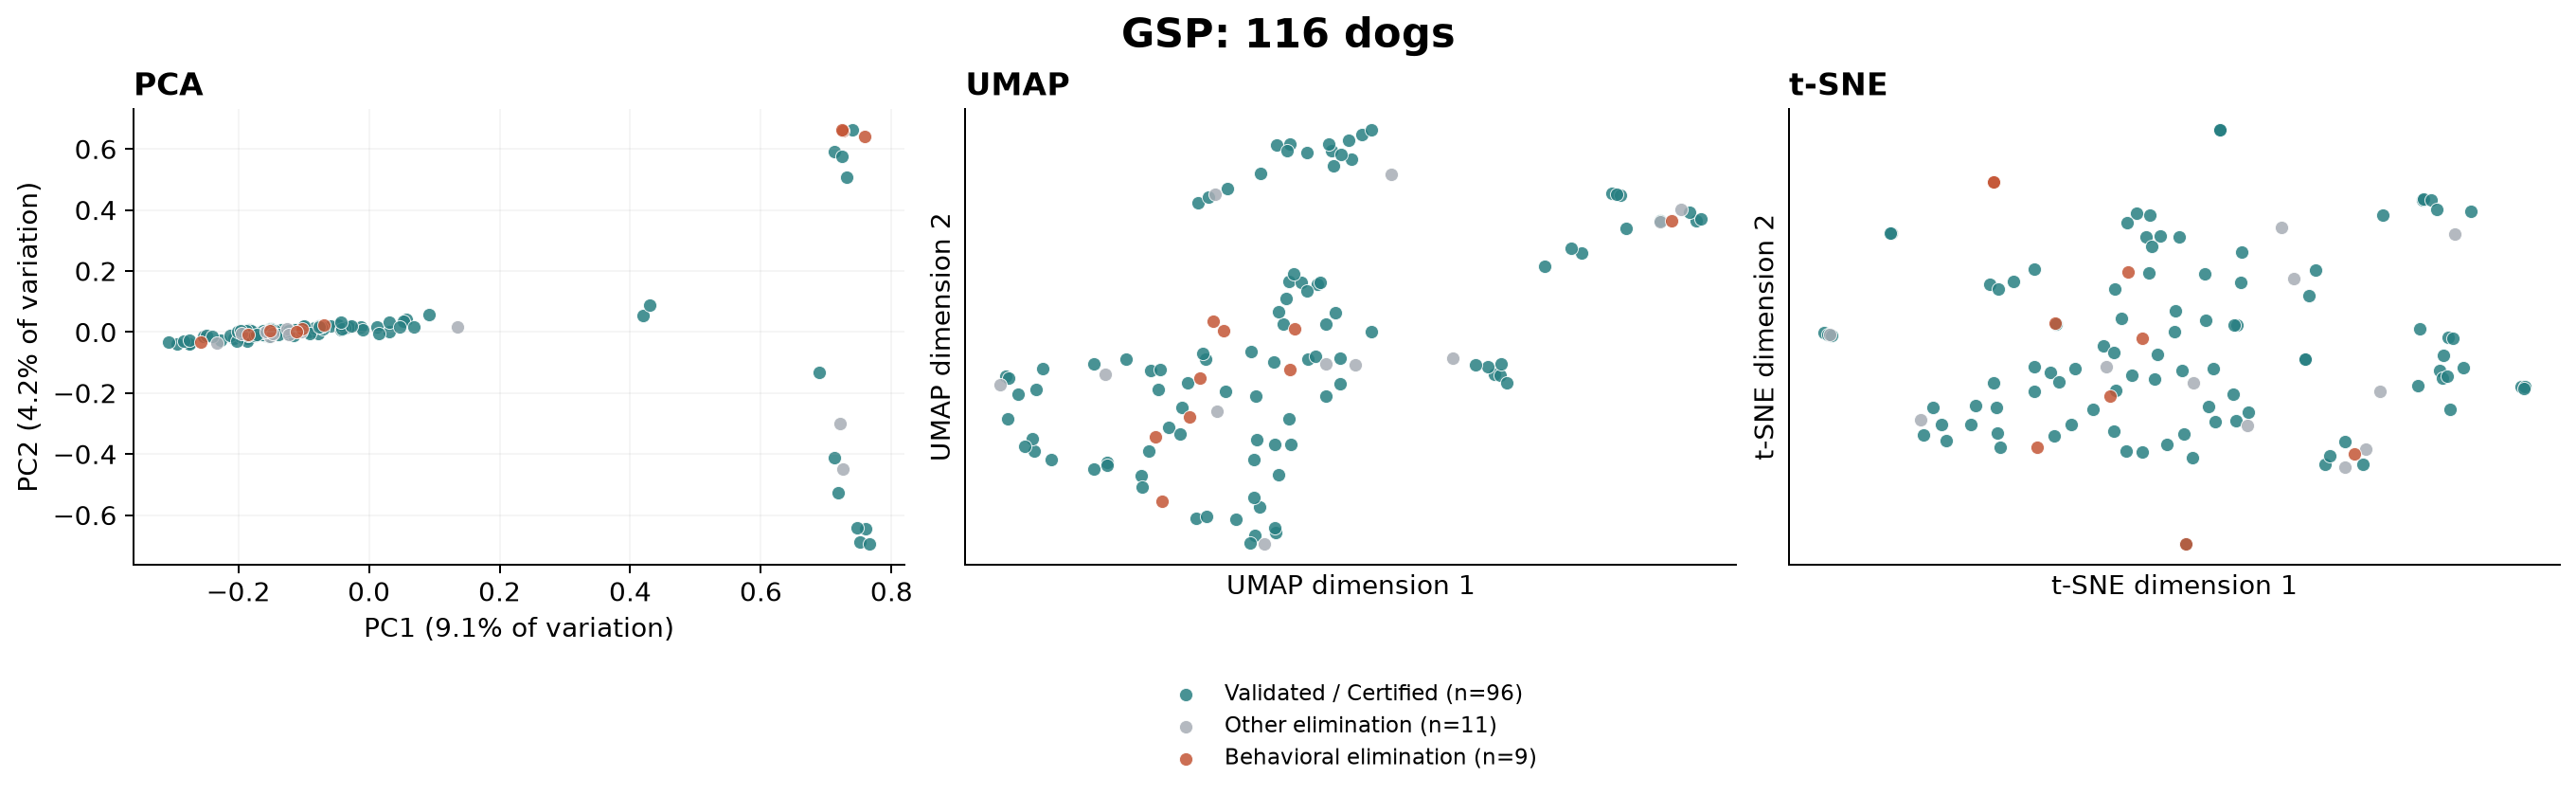

In [5]:
# Display the GSP-only maps to inspect genetic patterns within that breed.

display_figure("GSP_structure")

### (Visualization) Labrador Retrievers

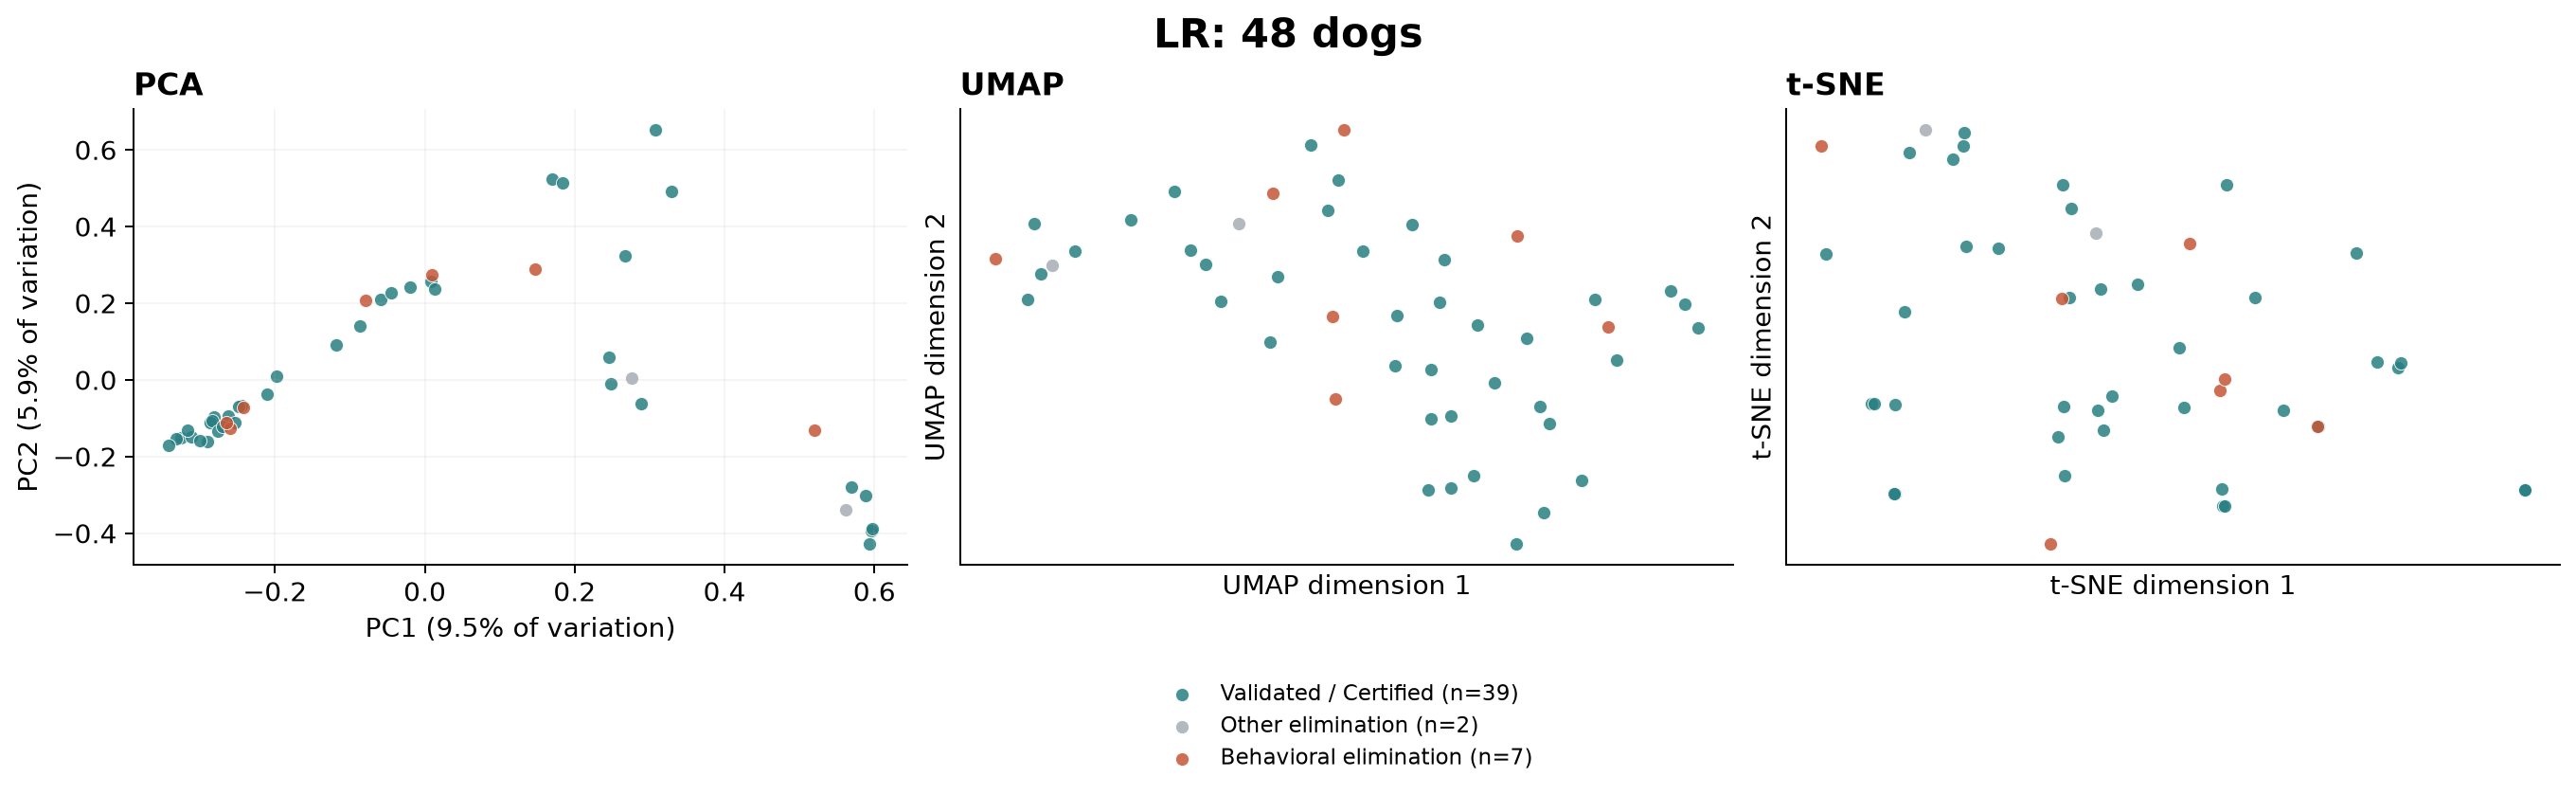

In [6]:
# Display the LR-only maps to inspect genetic patterns within that breed.

display_figure("LR_structure")

### (Visualization) Both Breeds

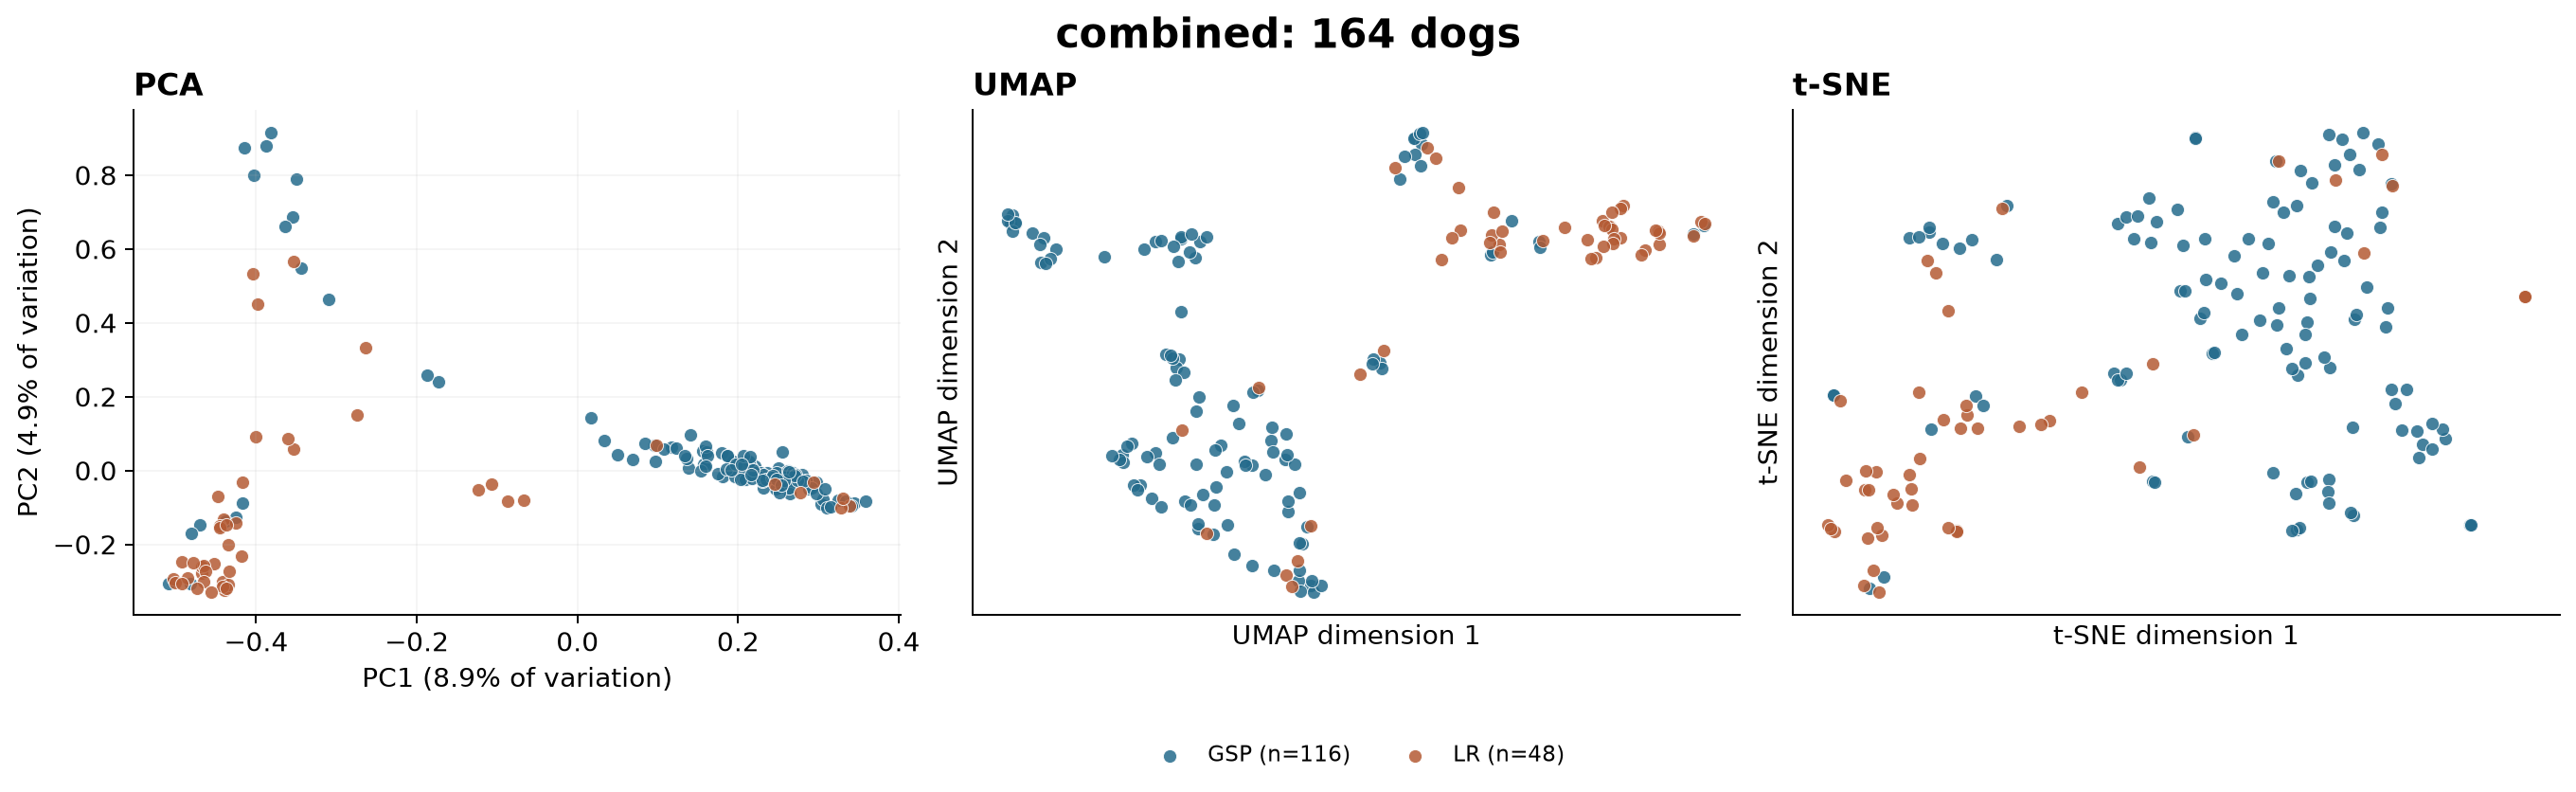

In [7]:
# Display the shared-marker view of both breeds for a descriptive comparison of genetic similarity.

display_figure("combined_structure")

### Variation Represented by PCA
- The first 20 PCs represent 37.1% of variation in the combined cohort, 41.9% in GSP and 63.7% in LR.

### (Data Transformation) Calculate Map Inputs

- Each PC is multiplied by the square root of its eigenvalue, giving more weight to components explaining more variation.


In [8]:
# Define how saved PCA coordinates are weighted by the square root of each eigenvalue.
# This makes the input calculation for UMAP and t-SNE explicit and checks for invalid values.

import numpy as np

def load_pca_scores(prefix, components=20):
    """Read PLINK components and weight each by its eigenvalue's square root."""
    with prefix.with_suffix('.eigenvec').open(encoding='utf-8') as handle:
        rows = [line.split() for line in handle if line.strip()]
    records = [dict(zip(rows[0], row)) for row in rows[1:]]
    eigenvalues=np.loadtxt(prefix.with_suffix('.eigenval'))
    assert np.isfinite(eigenvalues).all() and np.all(eigenvalues>=-1e-7)
    eigenvalues=np.maximum(eigenvalues,0)
    if components>len(eigenvalues):
        raise ValueError('Requested more components than the PCA provides')
    vectors=np.array([[float(row[f'PC{k+1}']) for k in range(components)] for row in records])
    scores=vectors*np.sqrt(eigenvalues[:components])
    assert np.isfinite(scores).all()
    return [row['IID'] for row in records], scores, eigenvalues

In [9]:
# Load the Labrador map inputs and check that they contain every recorded dog and 20 components.
# This confirms the dimensions used by the nonlinear maps.

dog_ids, map_inputs, eigenvalues = load_pca_scores(run_folder / "LR/03_pca")
assert map_inputs.shape == (manifest["summary"]["LR"]["dogs"], 20)
print(f"Labrador map inputs: {map_inputs.shape[0]} dogs, {map_inputs.shape[1]} components.")

Labrador map inputs: 48 dogs, 20 components.


### (Visualization) PCA Variation


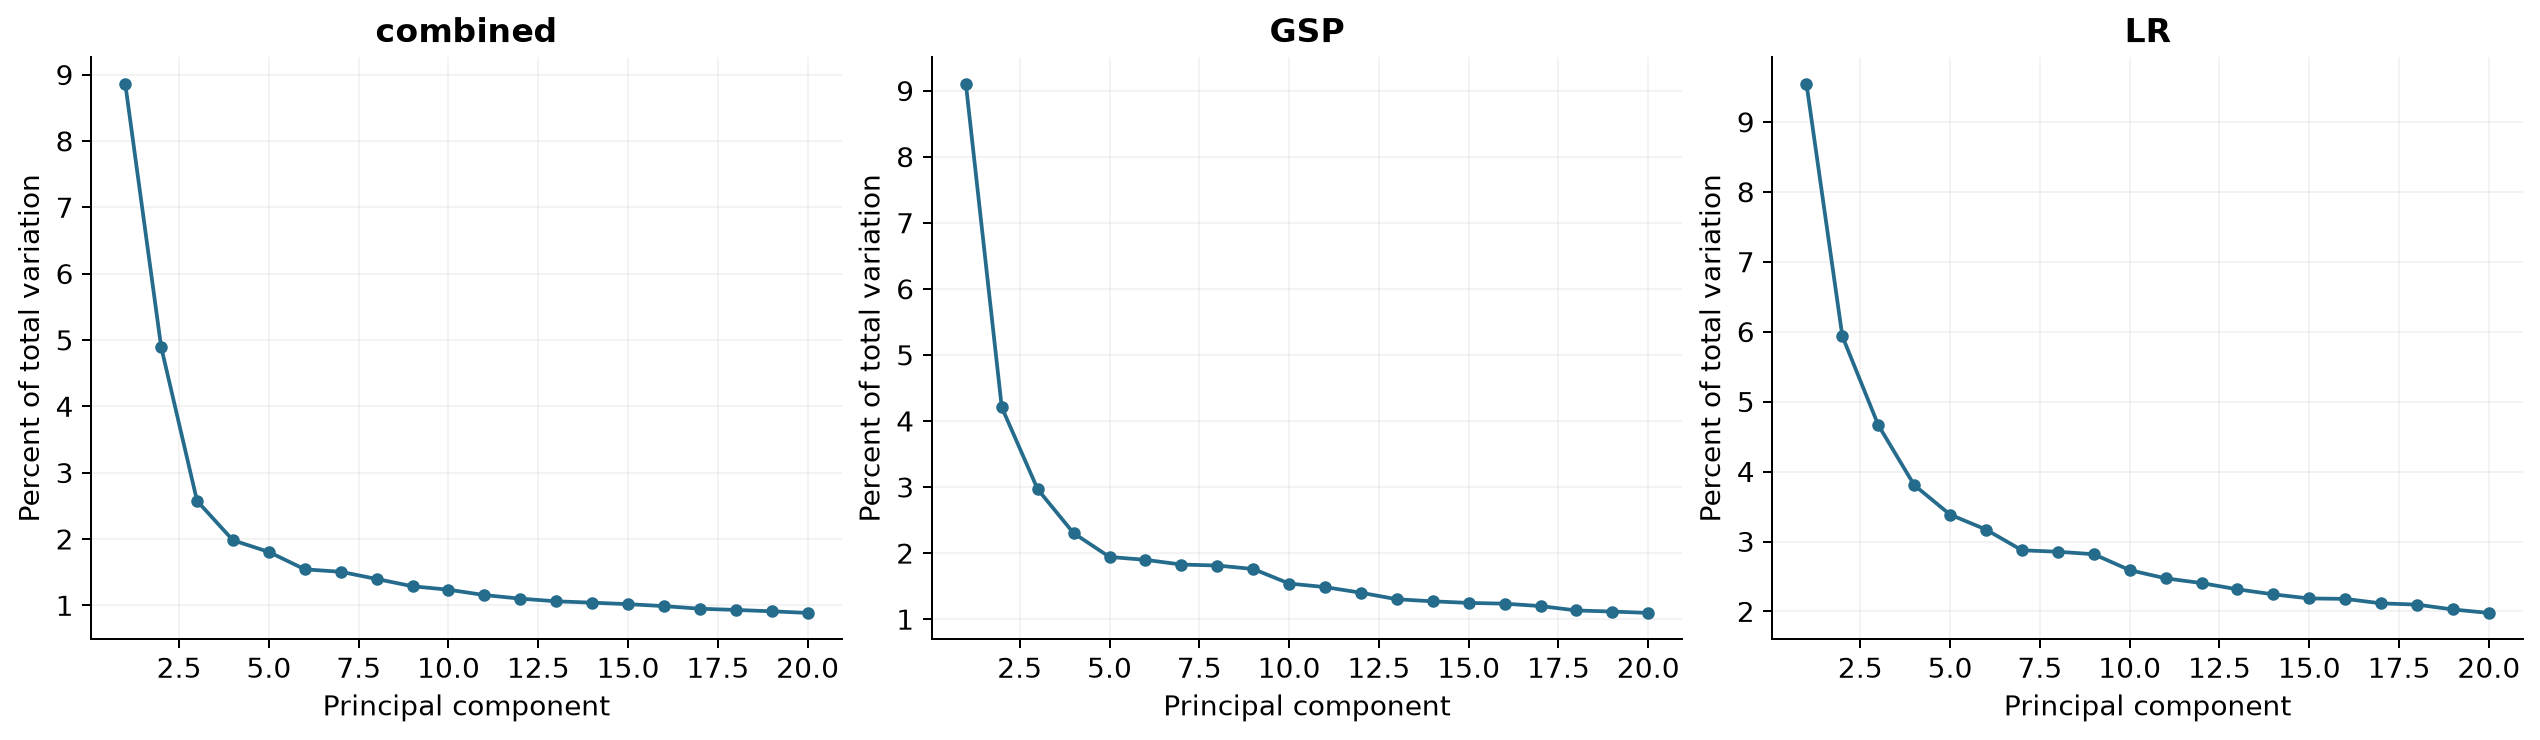

In [10]:
# Display the variance represented by the PCA components to show how much information the maps summarize.

display_figure("pca_variation")

### Sensitivity to Plot Settings: Alternative Layouts
- Alternative neighborhood settings and another seed show which patterns persist.
- Stable neighborhoods are more informative than a gap in one layout.

### (Visualization) German Shorthaired Pointers: Alternative Layouts

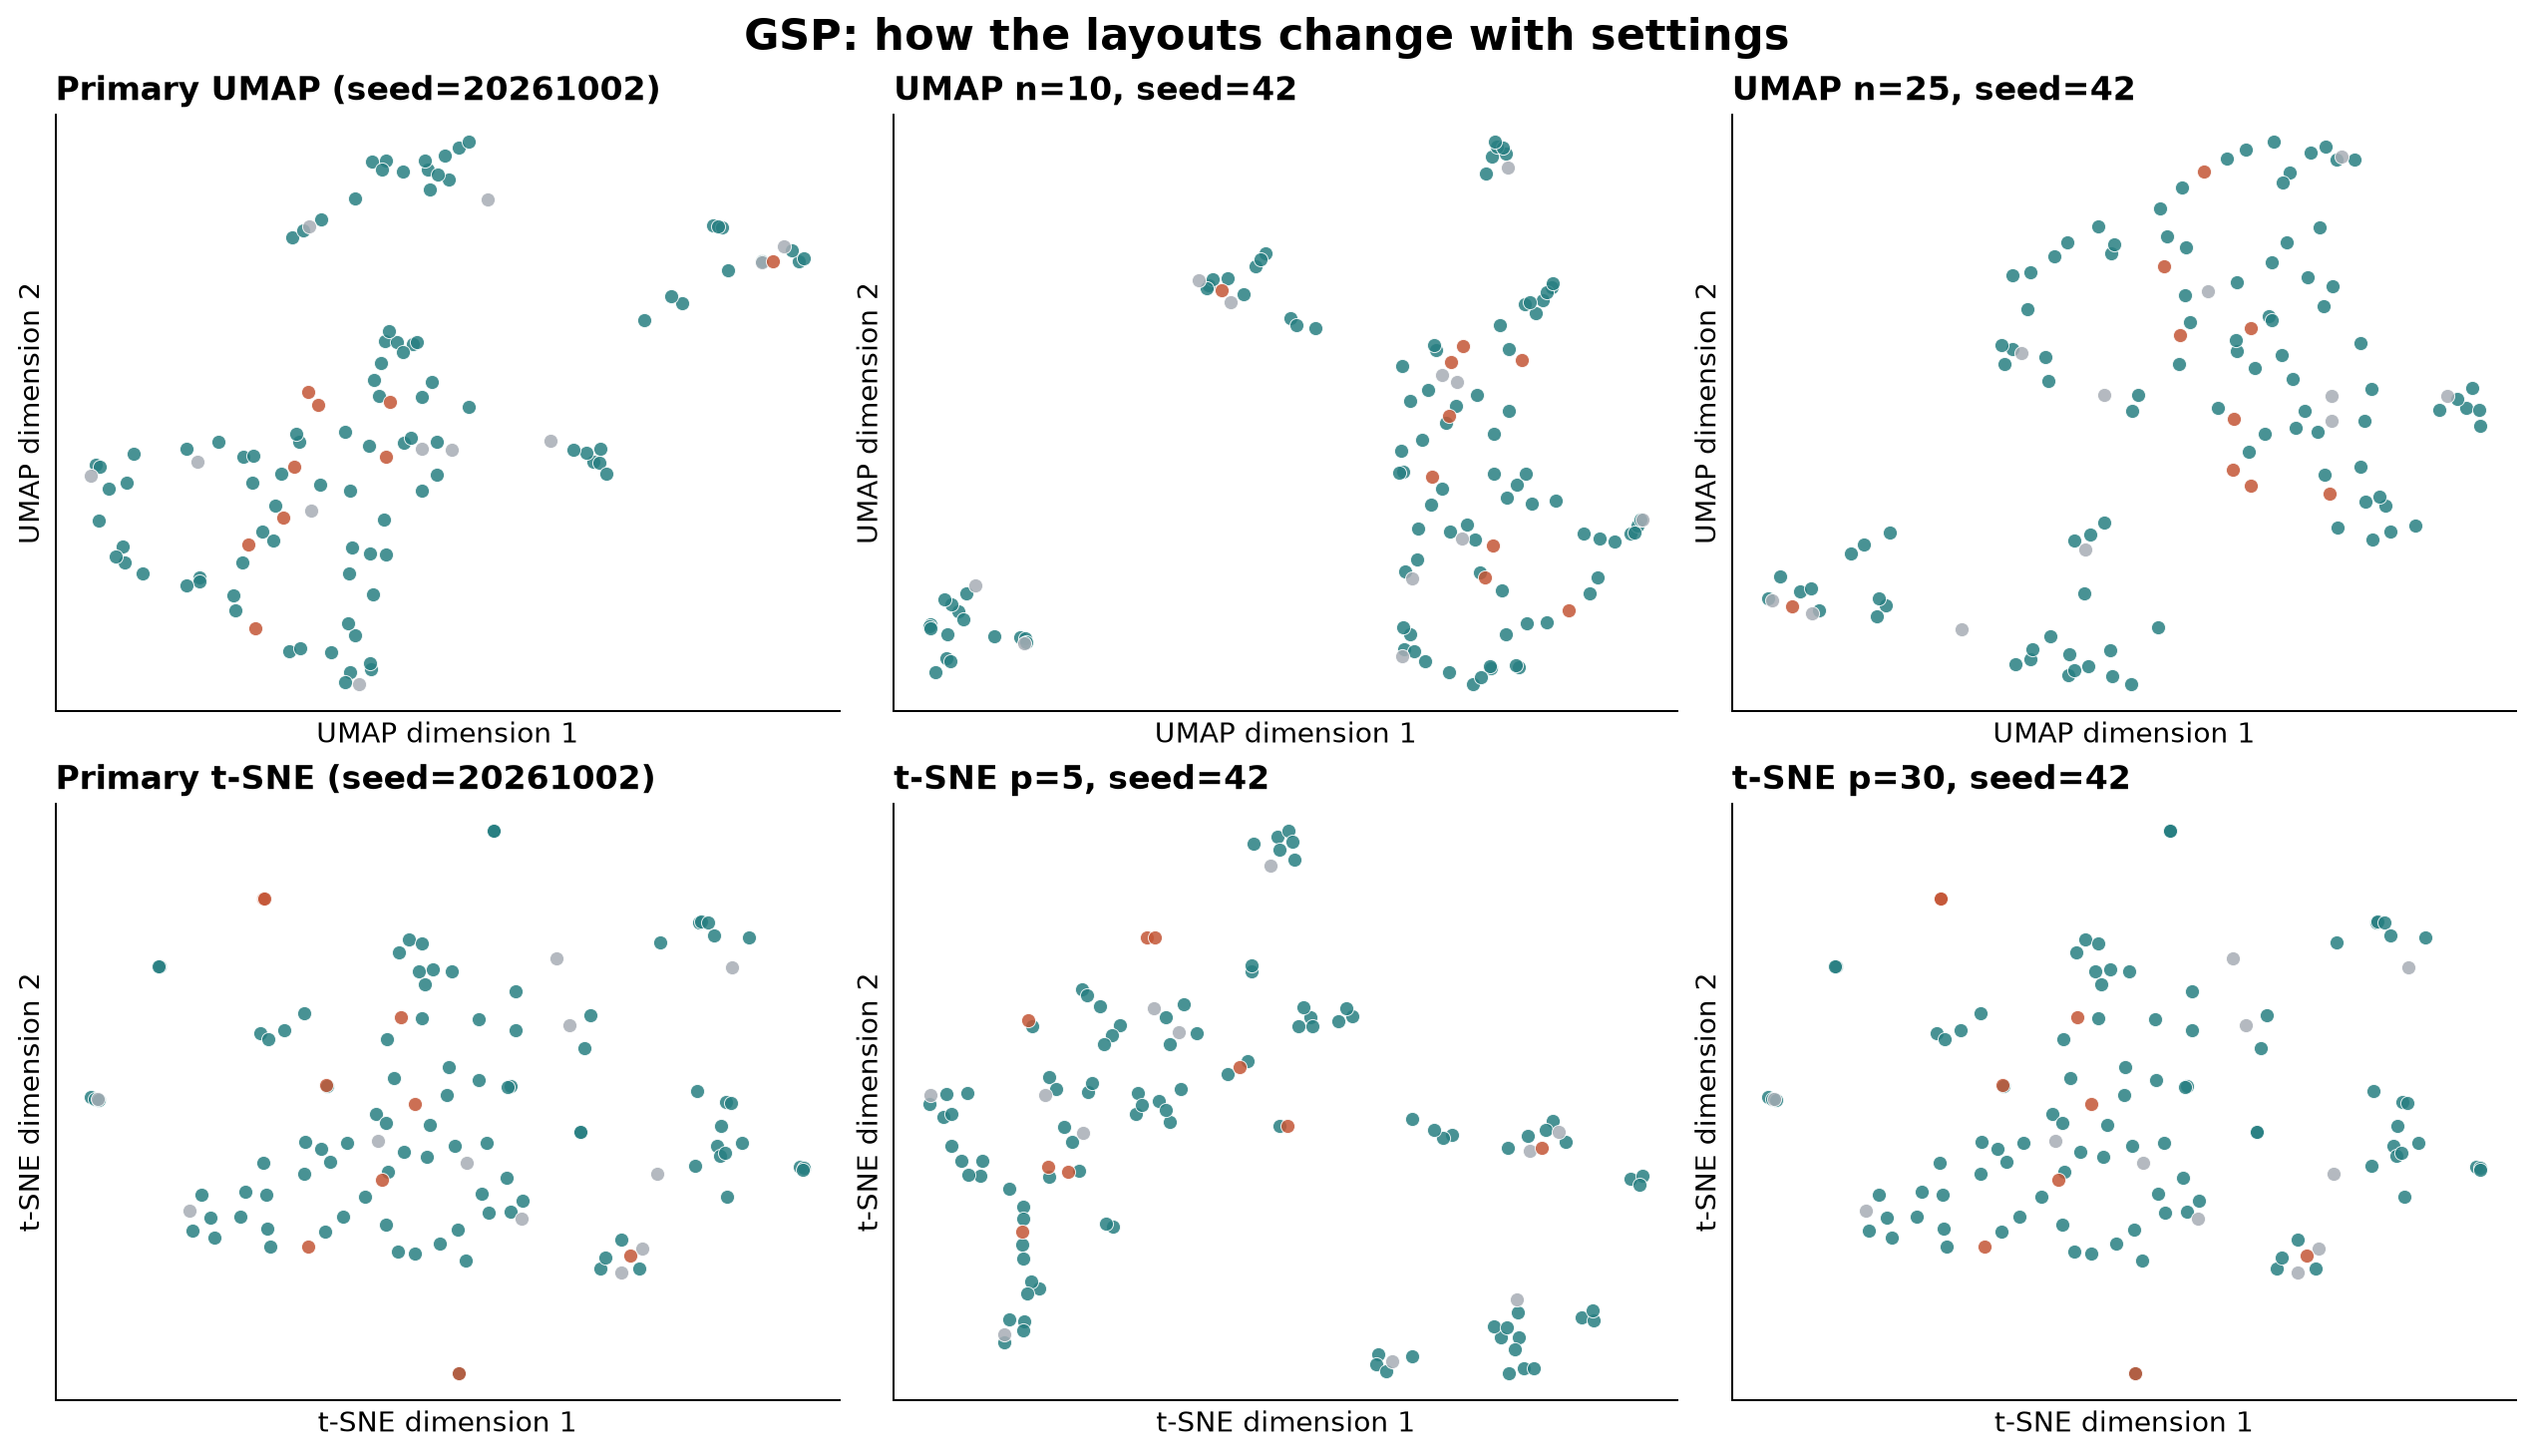

In [11]:
# Display alternative GSP layouts to assess dependence on mapping settings.

display_figure("GSP_layout_sensitivity")

### (Visualization) Labrador Retrievers: Alternative Layouts
- Labrador layouts change substantially with settings.
- Map fidelity measures preservation of neighborhoods, not biological validity.

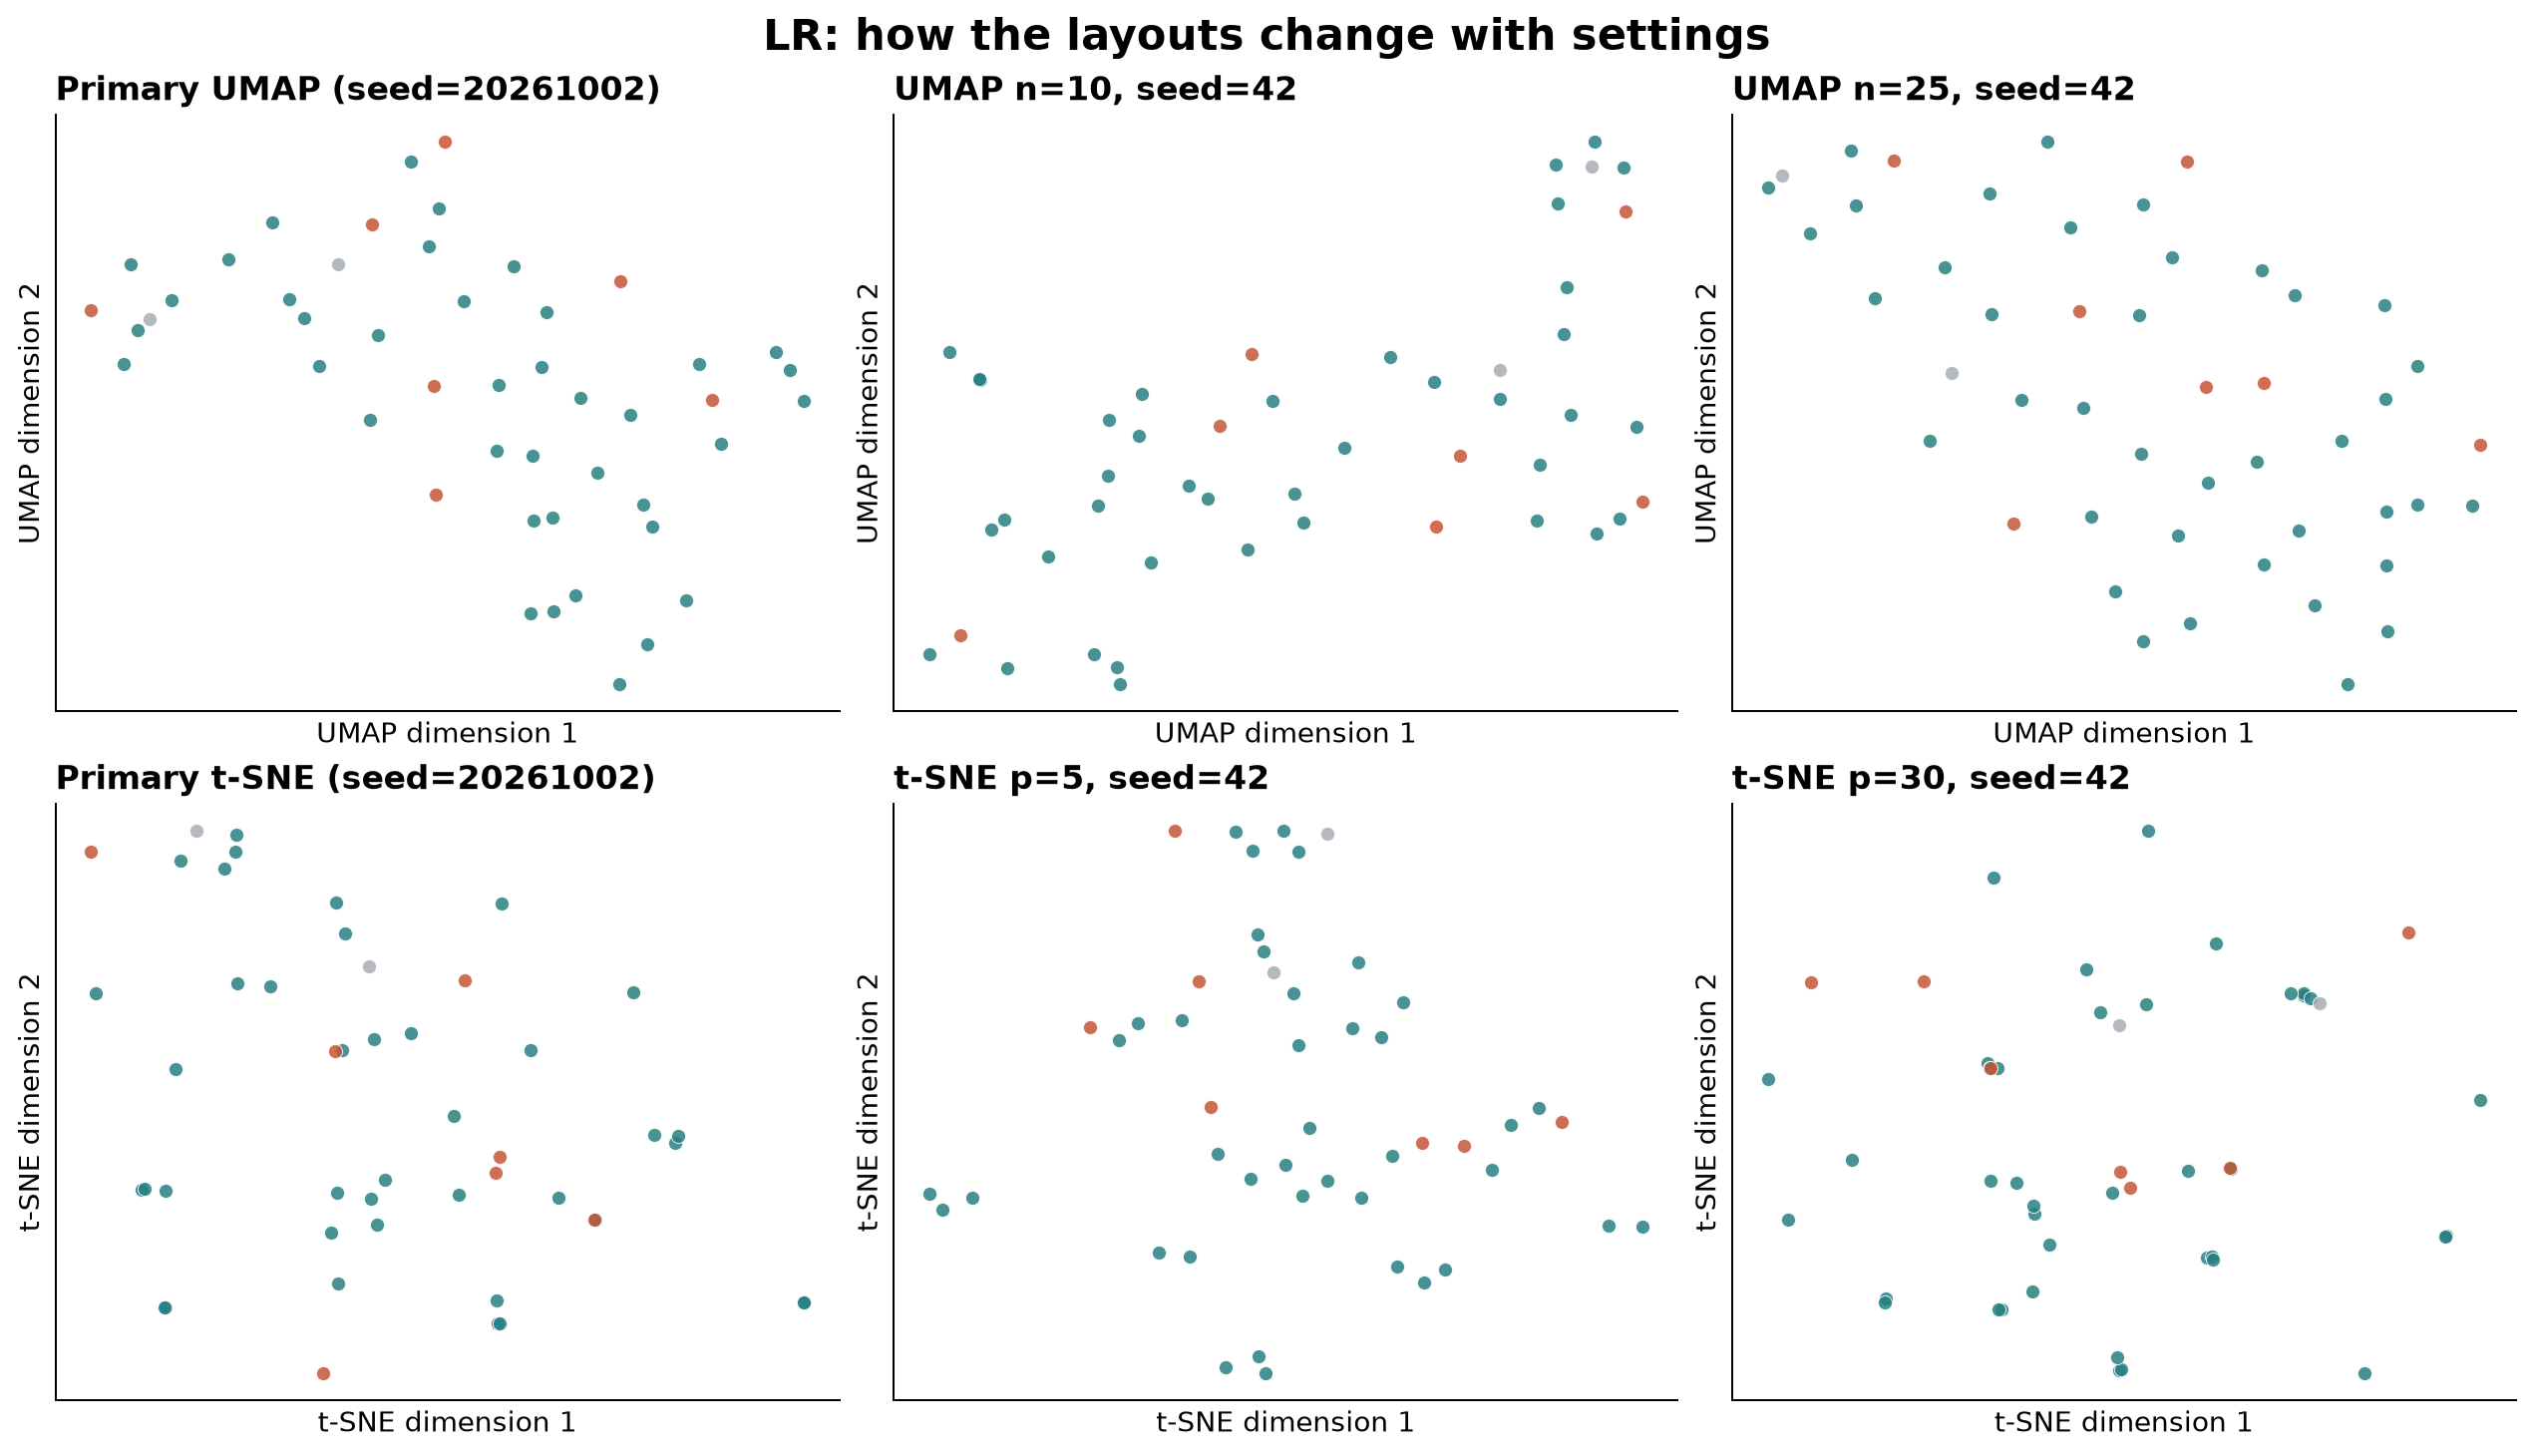

In [12]:
# Display alternative LR layouts to assess dependence on mapping settings.

display_figure("LR_layout_sensitivity")

### (Visualization) Both Breeds: Alternative Layouts

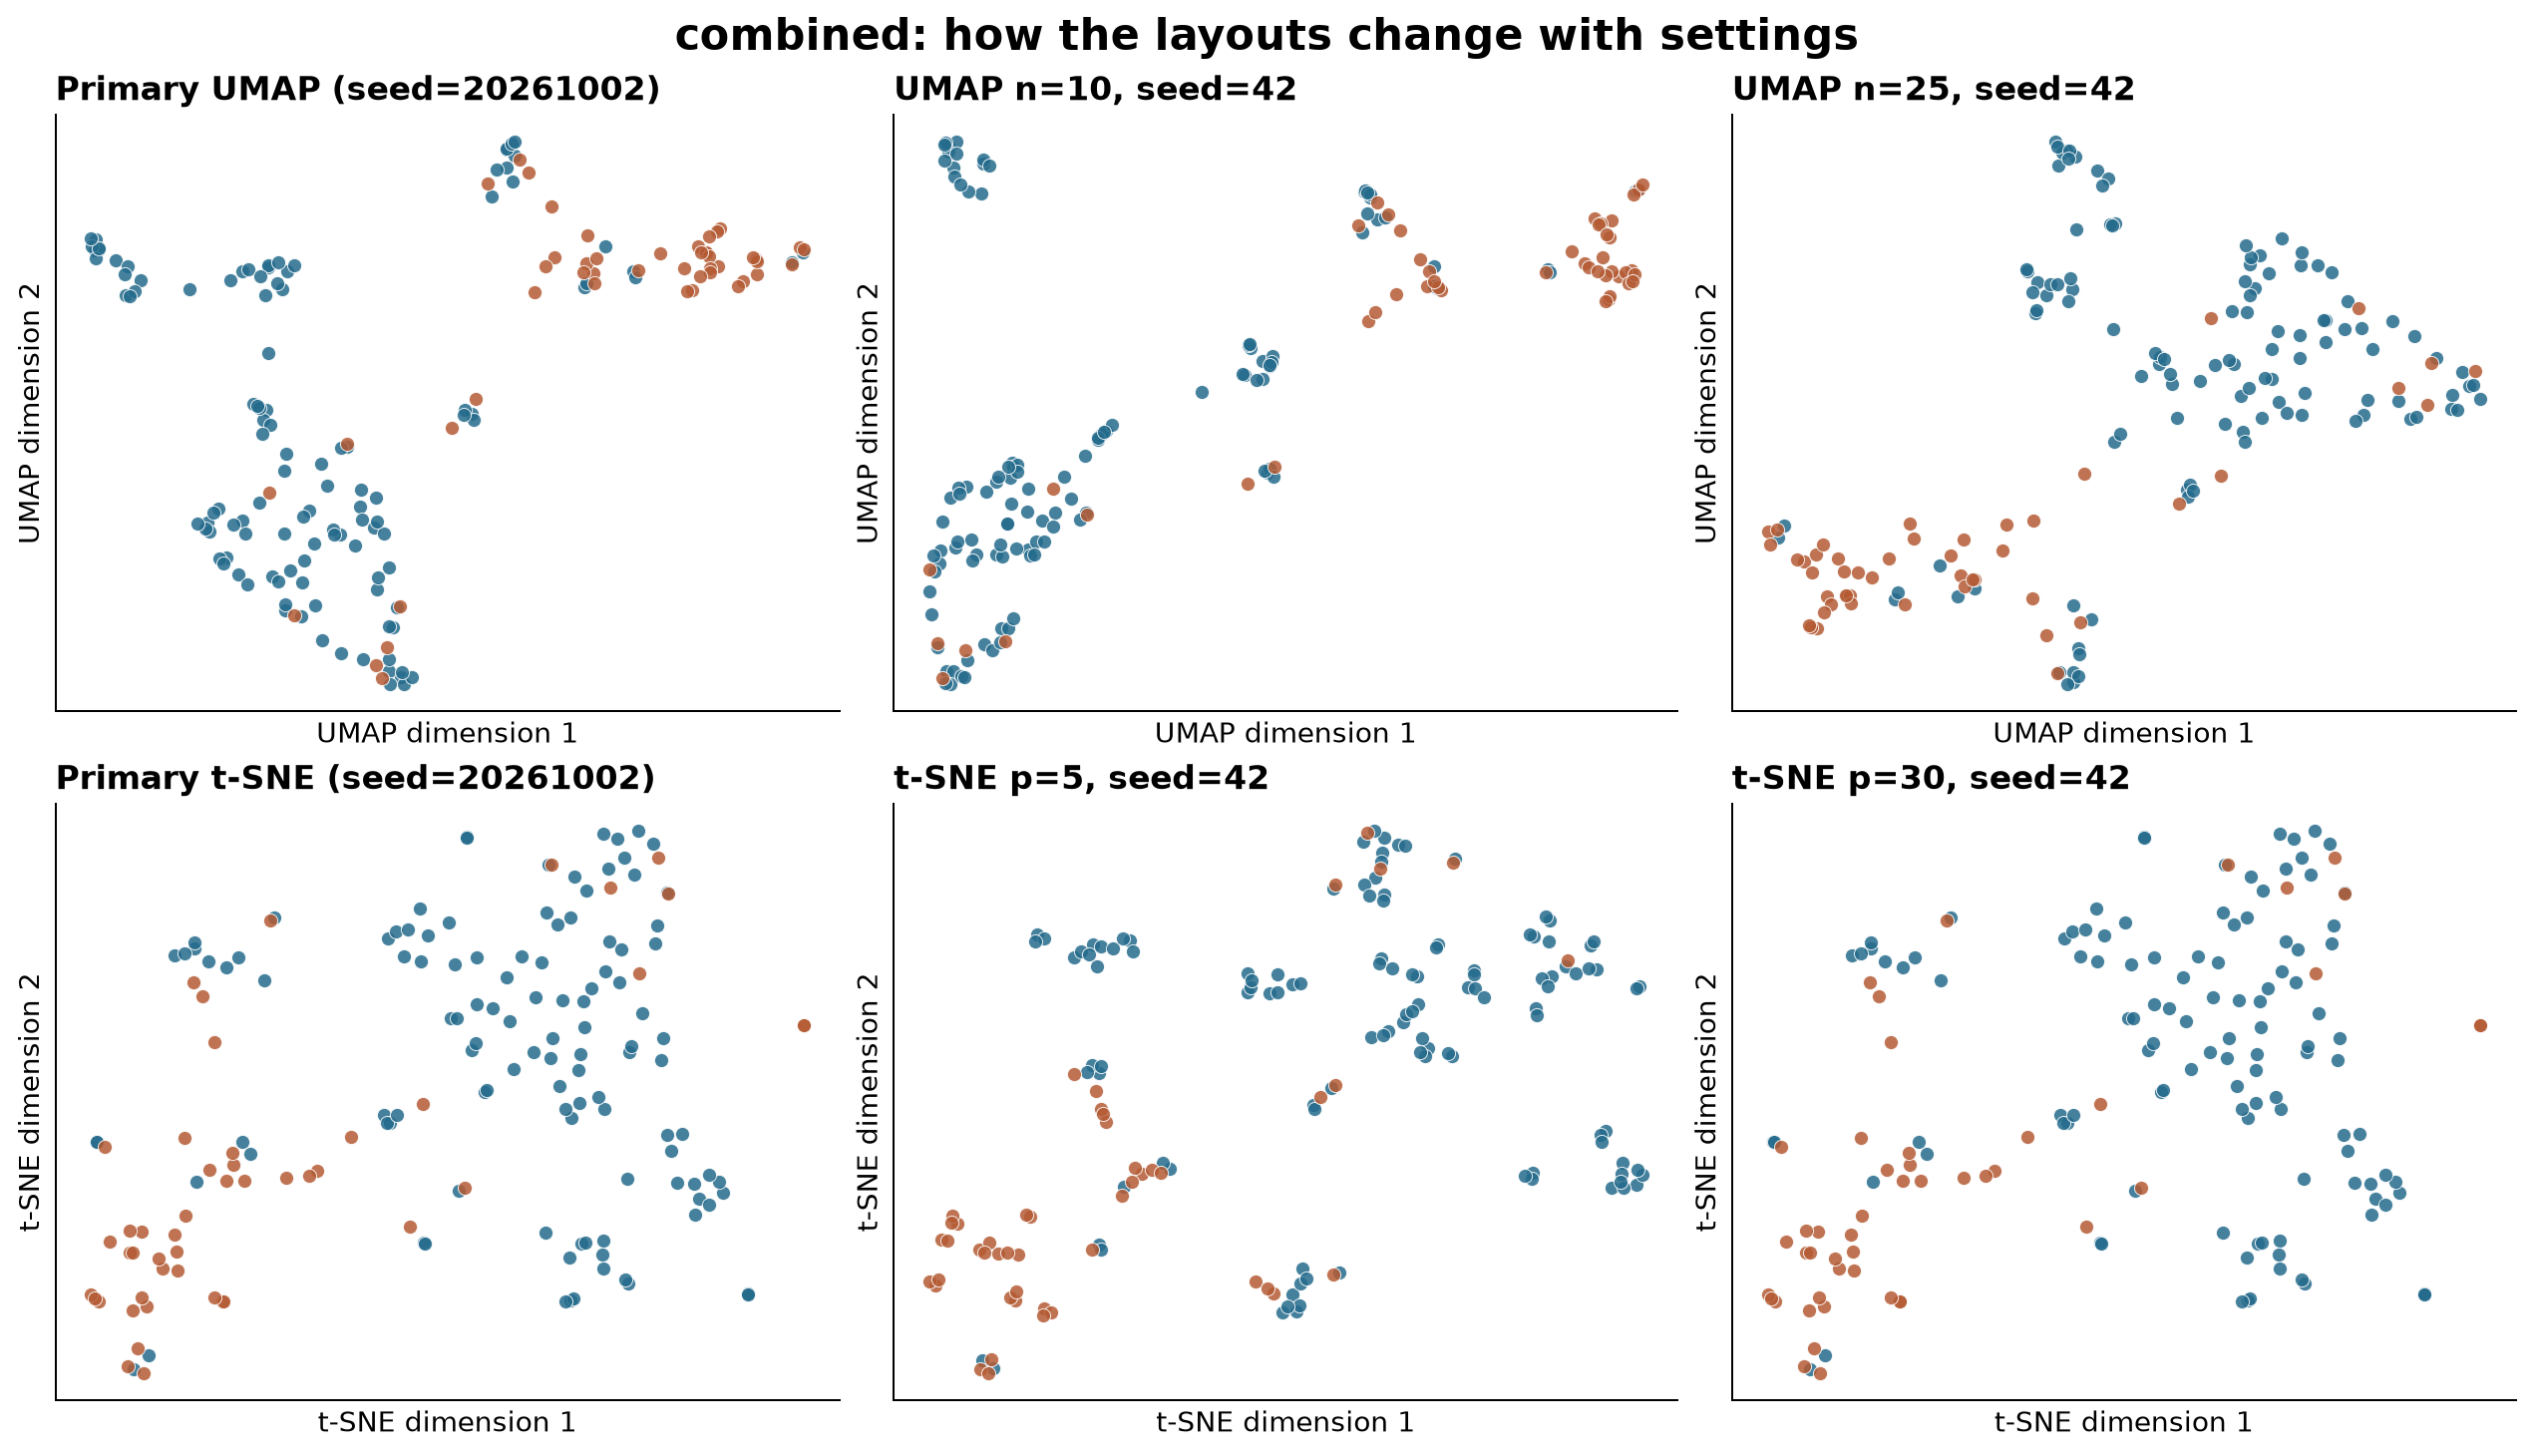

In [13]:
# Display alternative combined-breed layouts to assess dependence on mapping settings.

display_figure("combined_layout_sensitivity")

### (Consistency Check) Check Saved Results

- Input hashes and saved summaries confirm that all three views are present and match the recorded analysis.


In [14]:
# Recheck the original QC file hashes and confirm that all three structure views are present.
# These checks detect changed inputs or incomplete outputs before interpretation.

assert manifest["status"] == "complete"
assert manifest["source_qc_hashes_unchanged"]
for dataset in qc["datasets"]:
    for relative_path, expected in dataset["files"].items():
        assert hashlib.sha256((study_root / relative_path.replace(chr(92), "/")).read_bytes()).hexdigest() == expected
assert set(manifest["summary"]) == {"combined", "GSP", "LR"}
print("QC inputs verified; combined and both within-breed analyses completed.")

QC inputs verified; combined and both within-breed analyses completed.


### (Visualization) Relatedness Within Breeds

- PLINK estimates sharing by descent.
- There are 124 GSP pairs and 26 LR pairs at or above 0.25; none reach 0.90.
- Estimates depend on the sampled population and are not confirmed pedigrees.
- No dogs are excluded.


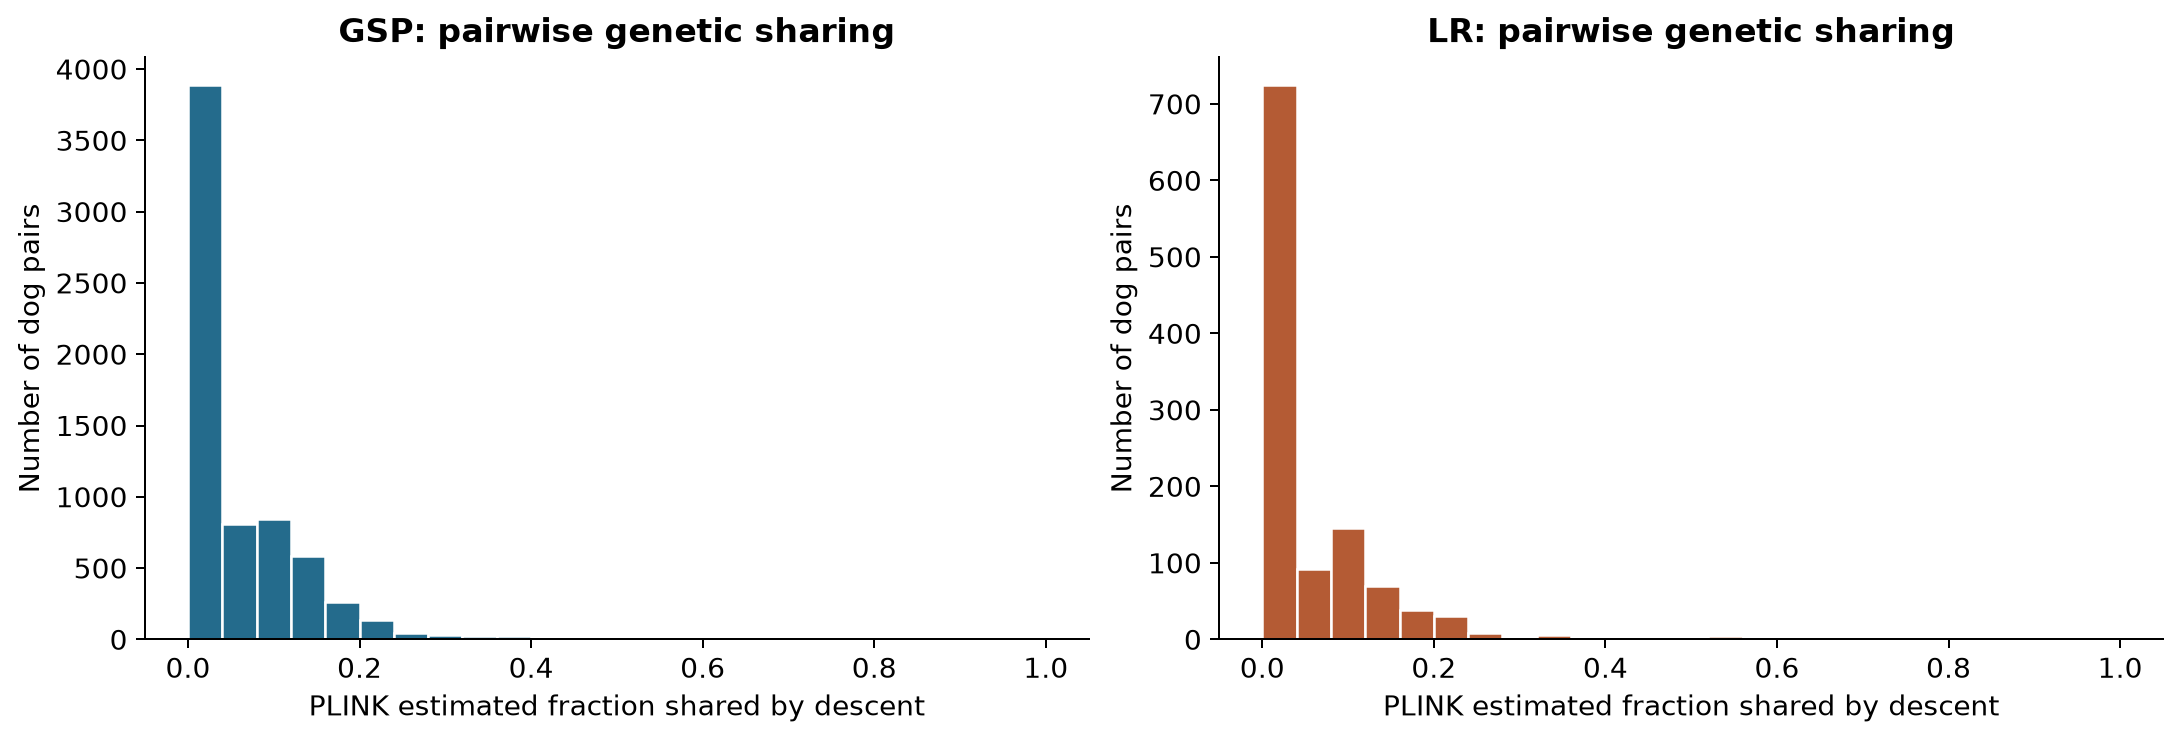

In [15]:
# Display within-breed genetic-sharing estimates to assess the need to account for related dogs.

display_figure("within_breed_relatedness")

### Implications for Association Tests

- Sharing estimates support accounting for relatedness even without clear clusters.
- Later models use a relationship matrix and sex adjustment; UMAP and t-SNE remain descriptive.
- Small case groups still require checks of model behavior.
- [Structure methods](../docs/methods/03%20Genetic%20structure%20and%20notebook%20figures.md) give the details.
